In [4]:
import numpy as np

In [5]:
def pat_partition(dataset_label, num_clients, num_classes, class_per_client=1, balance=False):
    dataidx_map = {}
    idxs = np.arange(len(dataset_label))

    # gom index theo class
    idx_for_each_class = [idxs[dataset_label == c] for c in range(num_classes)]

    class_num_per_client = [class_per_client] * num_clients

    for c in range(num_classes):
        # chọn client còn quota
        selected_clients = [i for i in range(num_clients) if class_num_per_client[i] > 0]
        if len(selected_clients) == 0:
            break

        # cắt theo đúng quy định trong code bạn
        selected_clients = selected_clients[:int(np.ceil((num_clients / num_classes) * class_per_client))]

        idx_list = idx_for_each_class[c]
        num_all = len(idx_list)
        k = len(selected_clients)

        num_per = num_all / k

        # chia sample
        if balance:
            num_samples = [int(num_per)] * (k - 1)
        else:
            num_samples = np.random.randint(
                max(num_per/10, 1), 
                num_per, 
                k - 1
            ).tolist()

        num_samples.append(num_all - sum(num_samples))

        # gán index cho client
        start = 0
        for cli, size in zip(selected_clients, num_samples):
            part = idx_list[start:start+size]
            if cli not in dataidx_map:
                dataidx_map[cli] = part
            else:
                dataidx_map[cli] = np.concatenate((dataidx_map[cli], part))
            start += size
            class_num_per_client[cli] -= 1

    return dataidx_map


In [2]:
def exdir_partition(dataset_label, num_clients, num_classes, class_per_client=2, alpha=0.5):
    y = np.array(dataset_label)

    # -------- LEVEL 1: allocate labels to clients ----------
    min_size_per_label = 0
    min_require_size_per_label = max(class_per_client * num_clients // num_classes // 2, 1)

    while min_size_per_label < min_require_size_per_label:
        clientidx_map = {c: [] for c in range(num_classes)}

        for i in range(num_clients):
            selected = np.random.choice(range(num_classes), class_per_client, replace=False)
            for c in selected:
                clientidx_map[c].append(i)

        min_size_per_label = min(len(clientidx_map[c]) for c in clientidx_map)

    # -------- LEVEL 2: allocate data idx ----------
    dataidx_map = {}
    min_size = 0
    min_require = 8
    N = len(y)

    while min_size < min_require:
        idx_batch = [[] for _ in range(num_clients)]

        for c in range(num_classes):
            idx_k = np.where(y == c)[0]
            np.random.shuffle(idx_k)

            proportions = np.random.dirichlet([alpha] * num_clients)

            proportions = np.array([
                p * (len(idx_batch[j]) < N/num_clients and j in clientidx_map[c])
                for j, p in enumerate(proportions)
            ])

            proportions /= proportions.sum()
            proportions = (np.cumsum(proportions) * len(idx_k)).astype(int)[:-1]

            # gán các phần
            parts = np.split(idx_k, proportions)

            # assign
            for j in range(num_clients):
                idx_batch[j] += parts[j].tolist()

            min_size = min(len(lst) for lst in idx_batch)

    # convert to final map
    for j in range(num_clients):
        dataidx_map[j] = np.array(idx_batch[j])

    return dataidx_map


Data size: (148517, 123)


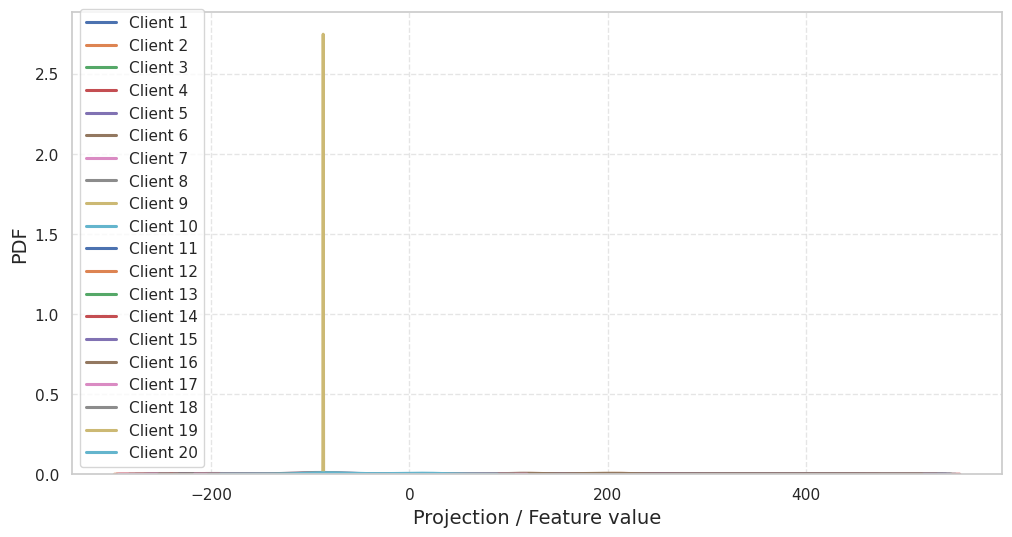

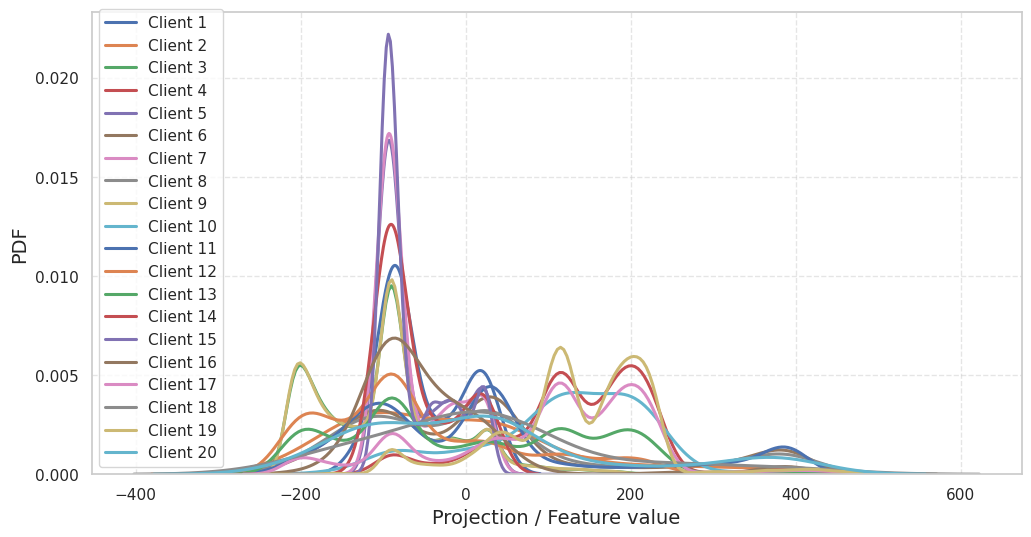

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
num_clients = 20
dir_path = "nslkdd/"
# === PCA ===
from sklearn.decomposition import PCA
import numpy as np

def pca_1d(X):
    pca = PCA(n_components=1)
    Z1 = pca.fit_transform(X)   # shape (N, 1)
    return Z1.squeeze(), pca



# === KDE ===
import matplotlib.pyplot as plt
import seaborn as sns

def visualize_kde(Z1, dataidx_map, title="Client PDFs (1D)"):
    plt.figure(figsize=(12, 6))
    sns.set(style="whitegrid")

    for cid, idxs in dataidx_map.items():
        sns.kdeplot(
            Z1[idxs],
            linewidth=2.2,
            label=f"Client {cid + 1}"
        )

    plt.title(title, fontsize=16)
    plt.xlabel("Projection / Feature value", fontsize=14)
    plt.ylabel("PDF", fontsize=14)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()


# ============================
# DEMO GIỐNG CODE BẠN
# ============================
train_data = np.genfromtxt(f'{dir_path}/rawdata/NSLKDD_Train.csv', delimiter=",")
test_data = np.genfromtxt(f'{dir_path}/rawdata/NSLKDD_Test.csv', delimiter=",")
data = np.concatenate((train_data, test_data), axis=0)
print('Data size:', data.shape)

    # split x, y
X = data[:, :-1]
y = data[:, -1]



num_classes = len(np.unique(y))

# PCA GLOBAL
Z1, pca_model = pca_1d(X) 

# ==== PARTITION PAT ====
pat_clients = pat_partition(
    dataset_label=y,
    num_clients=num_clients,
    num_classes=num_classes,
    class_per_client=2
)
visualize_kde(Z1, pat_clients, "")


# ==== PARTITION EXDIR ====
exdir_clients = exdir_partition(
    dataset_label=y,
    num_clients=num_clients,
    num_classes=num_classes,
    class_per_client=2,
    alpha=0.1
)
visualize_kde(Z1, exdir_clients, "")
